# Pipe Integrity Analysis Toolkit

This notebook walks through the workflow of a well-integrity analyst, step by step:

1. Load an ultrasonic wall-thickness scan of a well casing
2. Check data quality
3. Clean the data (remove noise)
4. Recognise normal geometry (collars)
5. Find thin areas
6. Measure and classify each defect
7. Quality-check the results
8. Visualize in 2D and 3D

The scan is **simulated**: 60 m of 7-inch casing with defects planted at known places, so the results can be checked against an answer key.
The analysis functions live in `simulate.py` and `detect.py`; this notebook calls them one step at a time and shows what each step does.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

from simulate import simulate, NOMINAL_WALL_MM, OUTER_DIAMETER_MM, depth_to_row
from detect import (find_missing_data, clean, find_collars, detect,
                    check_against_truth, WALL_LOSS_LIMIT_PCT)

# One colour scale for every image: red = thin, white = nominal, blue = thicker
VMIN = 3.0
VMAX = 2 * NOMINAL_WALL_MM - VMIN
CMAP = matplotlib.colormaps["RdBu"].copy()
CMAP.set_bad("#9e9e9e")   # missing data in grey

def show(data, depths, title, ax, a0=0, a1=360):
    # Draw a thickness map: depth down the page, angle a0..a1 across
    im = ax.imshow(data, aspect="auto", cmap=CMAP, vmin=VMIN, vmax=VMAX,
                   extent=[a0, a1, depths[-1], depths[0]], interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Angle around pipe (deg)")
    return im

## 1. The scan

An imaging tool scans all the way around the pipe as it moves down the well. "Unrolling" the pipe gives a 2D map:

- **rows** = depth (one reading every 1 cm)
- **columns** = angle around the pipe (one reading every 1°)
- **value** = remaining wall thickness in mm

Nominal (design) wall thickness is 9.19 mm for this casing.

Map size: (6000, 360) (depth readings x angle readings)
Depth range: 1200.0 to 1259.99 m


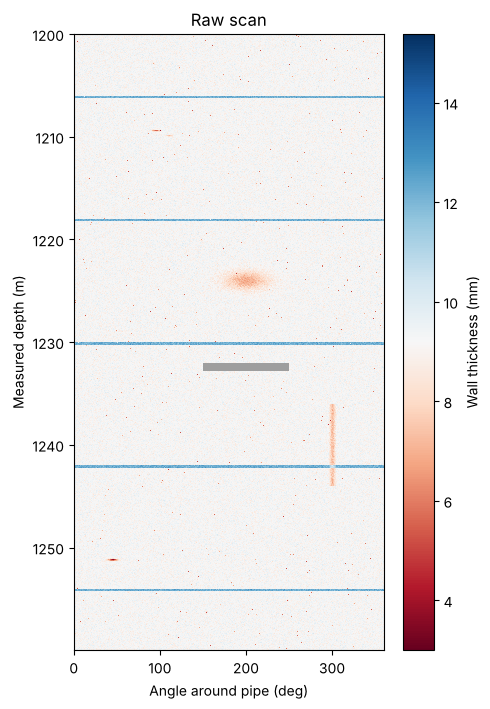

In [2]:
raw, truth, depths_m, collar_depths = simulate()
print("Map size:", raw.shape, "(depth readings x angle readings)")
print("Depth range:", depths_m[0], "to", round(depths_m[-1], 2), "m")

fig, ax = plt.subplots(figsize=(5, 8))
im = show(raw, depths_m, "Raw scan", ax)
ax.set_ylabel("Measured depth (m)")
fig.colorbar(im, ax=ax, label="Wall thickness (mm)")
plt.show()

## 2. Data quality: where is data missing?

A real tool can lose the echo, for example when gas bubbles are in the fluid. Those readings are stored as `NaN`.
We must **not** make defect calls where there is no data; we report the gap as low-confidence instead.

In [3]:
gaps = find_missing_data(raw, depths_m)
for top, bottom in gaps:
    print(f"No data from {top:.2f} m to {bottom:.2f} m -> low confidence")

No data from 1232.00 m to 1232.79 m -> low confidence


## 3. Clean the data with a median filter

The raw scan has random noise, including isolated "spike" readings that look like tiny thin spots.

A **median filter** replaces each reading with the middle value of its neighbours (here a 5×5 window):
- isolated spikes disappear, because one odd value never becomes the middle value
- the edges of real defects stay sharp

A mean (average) filter would blur the edges and make pits look shallower.

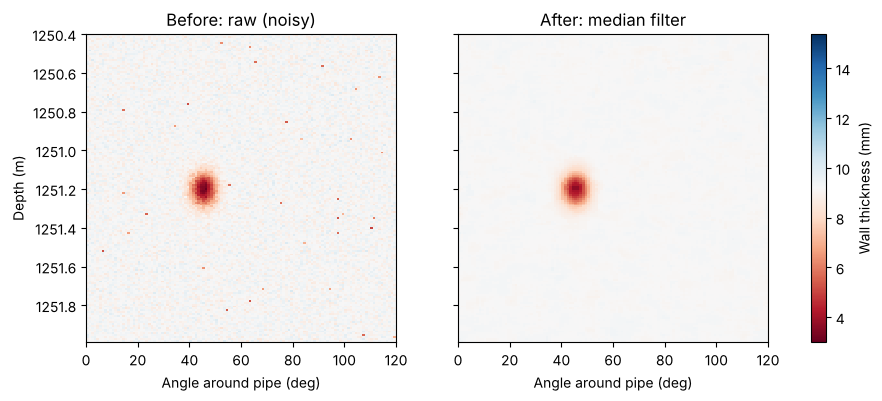

Noise (std. dev.) in an undamaged area:
  raw   : 0.299 mm
  smooth: 0.066 mm


In [4]:
smooth = clean(raw)

# Zoom on a small area to see the effect clearly
r1, r2 = depth_to_row(1250.4), depth_to_row(1252.0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
show(raw[r1:r2, 0:120], depths_m[r1:r2], "Before: raw (noisy)", axes[0], 0, 120)
im = show(smooth[r1:r2, 0:120], depths_m[r1:r2], "After: median filter", axes[1], 0, 120)
axes[0].set_ylabel("Depth (m)")
fig.colorbar(im, ax=axes, label="Wall thickness (mm)")
plt.show()

print("Noise (std. dev.) in an undamaged area:")
print("  raw   :", round(np.nanstd(raw[0:500, :]), 3), "mm")
print("  smooth:", round(np.nanstd(smooth[0:500, :]), 3), "mm")

## 4. Recognise normal geometry: collars

Casing comes in joints about 12 m long, joined by **collars**, which are thicker rings.
On the map they are full-width blue bands. They are normal, so we exclude them from the defect search.

In [5]:
collar_rows = find_collars(smooth)
labels_found = np.diff(collar_rows.astype(int)) == 1
print("Collars found at depths (m):", [round(d, 2) for d in depths_m[1:][labels_found]])

Collars found at depths (m): [np.float64(1205.95), np.float64(1217.95), np.float64(1229.95), np.float64(1241.95), np.float64(1253.95)]


## 5. Find thin areas

A reading is flagged if it has lost more than **10%** of the nominal wall:

$$\text{wall loss \%} = \frac{\text{nominal} - \text{measured}}{\text{nominal}} \times 100$$

So the limit is 90% of 9.19 mm = about 8.27 mm.

Reporting limit: 8.27 mm


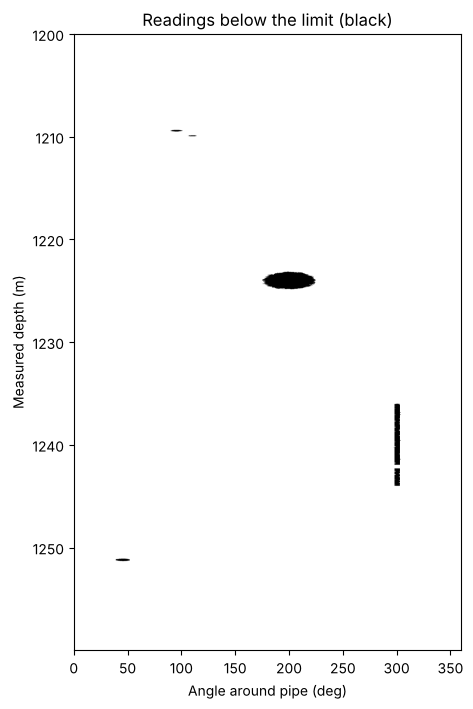

In [6]:
limit_mm = NOMINAL_WALL_MM * (1 - WALL_LOSS_LIMIT_PCT / 100)
print(f"Reporting limit: {limit_mm:.2f} mm")

thin = np.nan_to_num(smooth, nan=NOMINAL_WALL_MM) < limit_mm
thin[collar_rows, :] = False

fig, ax = plt.subplots(figsize=(5, 8))
ax.imshow(thin, aspect="auto", cmap="Greys", extent=[0, 360, depths_m[-1], depths_m[0]])
ax.set_title("Readings below the limit (black)")
ax.set_xlabel("Angle around pipe (deg)")
ax.set_ylabel("Measured depth (m)")
plt.show()

## 6. Measure and classify each defect

`detect()` runs the full workflow:

- **Group** touching thin readings into individual defects (and joins small gaps, so one groove isn't counted as many)
- **Measure** each one: depth, clock position (0° = 12 o'clock, 30° per hour), length, width, minimum wall and % wall loss
  - The deepest point is measured on *lightly* filtered (3×3) data. The 5×5 filter is good for *finding* defects, but it shrinks small pits and makes them look shallower: a dangerous under-call.
- **Classify** by shape: small = pitting, long and narrow = wear groove, broad = general corrosion
- **Rank** by severity (example bands; real limits come from the client)

In [7]:
table, smooth, thin, gaps, collar_rows = detect(raw, depths_m)
table

,Depth top (m),Depth of deepest point (m),Angle (deg),Clock position,Length (mm),Width (mm),Min wall (mm),Wall loss (%),Type,Severity
Defect #,,,,,,,,,,
1,1251.09,1251.20,45,2 o'clock,240,20,3.42,62.8,Pitting,Severe
2,1209.33,1209.40,95,3 o'clock,160,17,5.35,41.8,Pitting,High
3,1223.14,1224.03,203,7 o'clock,1710,78,6.65,27.7,General corrosion,Moderate
4,1209.86,1209.90,110,4 o'clock,90,12,6.73,26.7,Pitting,Moderate
5,1236.00,1237.87,299,10 o'clock,5950,11,7.15,22.2,Wear groove (axial),Moderate
6,1242.30,1242.68,300,10 o'clock,1700,8,7.23,21.4,Wear groove (axial),Moderate


## 7. Quality check: compare with the planted defects

Because the data is simulated, we know the right answer. A good result finds **every** real defect and reports **nothing** that isn't real.

In [8]:
check, false_calls = check_against_truth(table, truth)
print("False calls:", false_calls)
check

False calls: 0


,Planted defect,Depth (m),Angle (deg),Found?,Reported wall loss (%),Planted wall loss (%)
0,Pitting,1209.4,95,Yes (#2),41.8,45
1,Pitting,1209.9,110,Yes (#4),26.7,30
2,General corrosion,1224.0,200,Yes (#3),27.7,25
3,Wear groove,1240.0,300,"Yes (#5, #6)",22.2,20
4,Severe pit,1251.2,45,Yes (#1),62.8,65


Every planted defect was found and there are no false calls. The groove at 300° appears as defects #5 and #6 because it crosses the collar at 1242 m, which is excluded as normal geometry.

## 8. Visualize

### Full scan with detected defects

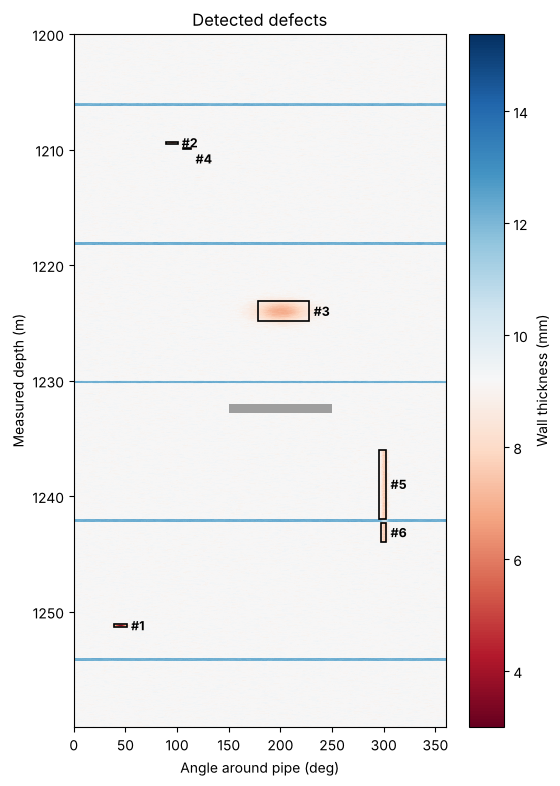

In [9]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(6, 9))
im = show(smooth, depths_m, "Detected defects", ax)
for num, d in table.iterrows():
    top, height = d["Depth top (m)"], d["Length (mm)"] / 1000
    width_deg = d["Width (mm)"] / (np.pi * OUTER_DIAMETER_MM) * 360
    left = d["Angle (deg)"] - width_deg / 2
    ax.add_patch(Rectangle((left, top), width_deg, height, fill=False, edgecolor="black", lw=1.2))
    ax.text(left + width_deg + 4, top + height / 2 + (0.9 if num == 4 else 0), f"#{num}",
            fontsize=9, va="center", weight="bold")
ax.set_ylabel("Measured depth (m)")
fig.colorbar(im, ax=ax, label="Wall thickness (mm)")
plt.show()

### Close-up and thickness profile of the worst defect

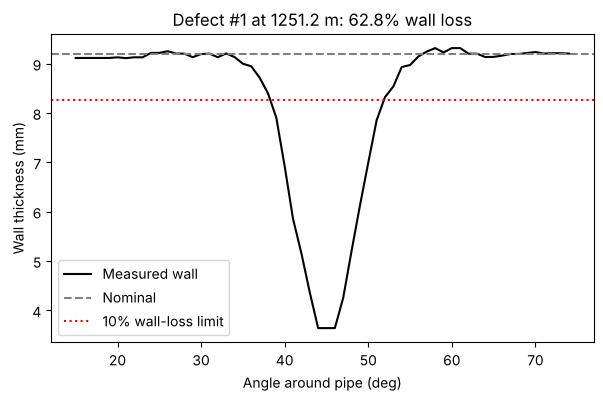

In [10]:
worst = table.iloc[0]
r = depth_to_row(worst["Depth of deepest point (m)"])
c = worst["Angle (deg)"]
c1, c2 = c - 30, c + 30

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(c1, c2), smooth[r, c1:c2], color="black", label="Measured wall")
ax.axhline(NOMINAL_WALL_MM, ls="--", color="grey", label="Nominal")
ax.axhline(limit_mm, ls=":", color="red", label="10% wall-loss limit")
ax.set_title(f"Defect #1 at {worst['Depth of deepest point (m)']} m: {worst['Wall loss (%)']}% wall loss")
ax.set_xlabel("Angle around pipe (deg)")
ax.set_ylabel("Wall thickness (mm)")
ax.legend()
plt.show()

### 3D view

The flat map is wrapped back into a pipe. Each reading has a depth and an angle θ, so its 3D position is:

$$x = r\cos\theta, \quad y = r\sin\theta, \quad z = \text{depth}$$

This shows the 8 m section around the general-corrosion area (defect #3). Running `main.py` also saves an interactive version, `outputs/pipe_3d.html`, that you can rotate in a browser.

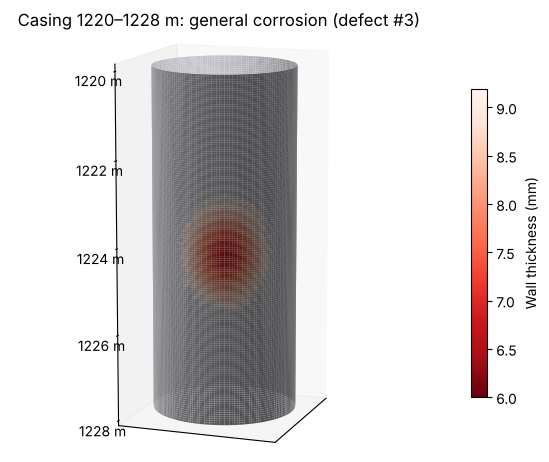

In [11]:
top, bottom = depth_to_row(1220), depth_to_row(1228)
section = np.nan_to_num(smooth[top:bottom:5], nan=NOMINAL_WALL_MM)
section = np.concatenate([section, section[:, :1]], axis=1)   # close the ring
theta = np.radians(np.arange(0, 361))
z = depths_m[top:bottom:5]
R = OUTER_DIAMETER_MM / 2 / 1000 * 20      # radius exaggerated 20x to be visible

X = R * np.cos(theta)[None, :] * np.ones((len(z), 1))
Y = R * np.sin(theta)[None, :] * np.ones((len(z), 1))
Z = -z[:, None] * np.ones((1, len(theta)))
# Tighter colour range for this view, so the corrosion stands out:
# dark red = thinnest, light grey = full nominal wall
norm = matplotlib.colors.Normalize(vmin=6.0, vmax=NOMINAL_WALL_MM)
colors = matplotlib.colormaps["Reds_r"](norm(section))
colors[section > NOMINAL_WALL_MM - 0.3] = (0.82, 0.82, 0.85, 1)   # undamaged steel

fig = plt.figure(figsize=(7, 8))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, facecolors=colors, rstride=1, cstride=2, linewidth=0,
                shade=True, lightsource=matplotlib.colors.LightSource(azdeg=225, altdeg=35))
ax.view_init(elev=12, azim=200)                     # look at the 200 deg side
ax.set_box_aspect((1, 1, 2.2))
ax.set_zticks(-np.arange(1220, 1229, 2))
ax.set_zticklabels([f"{d} m" for d in range(1220, 1229, 2)])
ax.set_xticks([]); ax.set_yticks([])
ax.grid(False)
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap="Reds_r")
fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.08, label="Wall thickness (mm)")
ax.set_title("Casing 1220–1228 m: general corrosion (defect #3)")
plt.show()

## What I learned

- **Filtering is a trade-off.** The first version used the same 5×5 filter for finding and measuring, and it under-reported a 65% pit as 40%. Detecting on smooth data but measuring on detailed data fixed it.
- **Resolution matters.** At 5 cm spacing, small pits were missed entirely; at 1 cm all were found. This is why high-resolution imaging tools are valuable.
- **Context prevents false calls.** Collars, missing data and a groove crossing a collar each needed rules based on how a real well is built.